# Prediction intervals and coverage
**Sheima Alameeri, PhD**

A follow-up to *Gaussian-process regression: prediction and uncertainty*. This educational example uses only synthetic data and is separate from my dissertation research code.

We distinguish uncertainty about a smooth function from uncertainty about a new noisy observation, then compare nominal and empirical coverage. Run the cells in order; no dataset download, GPU, or API key is needed.

## 1. The observation model

$$
y_i=f(x_i)+\varepsilon_i,\qquad \varepsilon_i\overset{\mathrm{iid}}{\sim}\mathcal{N}(0,\sigma^2).
$$

Here $x_i$ is an input, $f(x_i)$ is the unknown function value, $y_i$ is the observed response, and $\sigma$ is the noise standard deviation. We use a zero-mean Gaussian process with an RBF covariance:

$$
k(x,x')=a^2\exp\!\left[-\frac{(x-x')^2}{2\ell^2}\right].
$$

The amplitude $a$ controls function variation; the length scale $\ell$ controls smoothness. Hyperparameters are fixed to keep the uncertainty calculation transparent.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm

SEED = 2026
rng = np.random.default_rng(SEED)
sigma_true = 0.35
x_train = np.linspace(-3, 3, 28)
x_test = np.linspace(-3, 3, 400)

def truth(x):
    return np.sin(1.4 * x) + 0.25 * np.cos(2.5 * x)

def kernel(x, z):
    return 1.2**2 * np.exp(-0.5 * ((x[:, None] - z[None, :]) / 0.9)**2)

y_train = truth(x_train) + rng.normal(0, sigma_true, x_train.size)
y_test = truth(x_test) + rng.normal(0, sigma_true, x_test.size)


## 2. Posterior prediction

Let $X$ denote the training inputs, $\mathbf y$ the response vector, $K= k(X,X)$ the training covariance matrix, $\mathbf k_*=k(X,x_*)$ the covariance vector, and $I$ the identity matrix. Conditional on the model and training data $\mathcal D$:

$$
\mu_*=\mathbf k_*^{\mathsf T}(K+\sigma^2 I)^{-1}\mathbf y,
$$

$$
v_{f,*}=k(x_*,x_*)-\mathbf k_*^{\mathsf T}(K+\sigma^2 I)^{-1}\mathbf k_*.
$$

We use Cholesky solves in code rather than computing the inverse. A small diagonal jitter stabilizes the solve.

For a new observation with independent noise:

$$
f_*\mid\mathcal D\sim\mathcal N(\mu_*,v_{f,*}),\qquad
y_*\mid\mathcal D\sim\mathcal N(\mu_*,v_{y,*}),\qquad
v_{y,*}=v_{f,*}+\sigma^2.
$$

The latent interval describes $f_*$. The prediction interval describes $y_*$ and is wider because it includes observation noise.

In [2]:
def posterior(y, sigma_model):
    covariance = kernel(x_train, x_train)
    factor = cho_factor(covariance + (sigma_model**2 + 1e-10) * np.eye(len(x_train)))
    cross = kernel(x_train, x_test)
    mean = cross.T @ cho_solve(factor, y)
    latent_var = np.maximum(1.2**2 - np.sum(cross * cho_solve(factor, cross), axis=0), 0)
    return mean, latent_var, latent_var + sigma_model**2

mean, latent_var, observation_var = posterior(y_train, sigma_true)
assert np.allclose(observation_var - latent_var, sigma_true**2)
assert np.all(latent_var >= 0)


## 3. Pointwise intervals

For nominal coverage $1-\alpha$, let $z_{1-\alpha/2}$ be the corresponding standard normal quantile. For 95% intervals, $\alpha=0.05$ and this quantile is approximately $1.96$.

$$
I_f(x_*)=\left[\mu_*-z_{1-\alpha/2}\sqrt{v_{f,*}},\ \mu_*+z_{1-\alpha/2}\sqrt{v_{f,*}}\right],
$$

$$
I_y(x_*)=\left[\mu_*-z_{1-\alpha/2}\sqrt{v_{y,*}},\ \mu_*+z_{1-\alpha/2}\sqrt{v_{y,*}}\right].
$$

These intervals apply to each input separately. They are not a simultaneous band covering an entire curve with 95% probability.

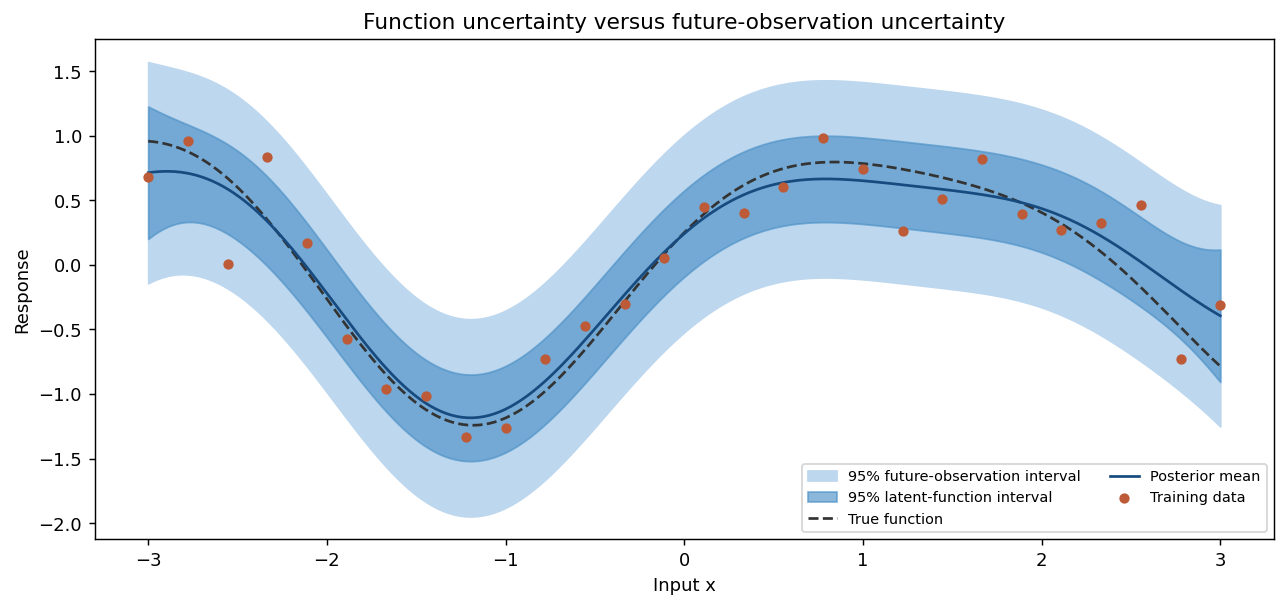

In [3]:
z = norm.ppf(0.975)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.fill_between(x_test, mean-z*np.sqrt(observation_var), mean+z*np.sqrt(observation_var), color='#bdd7ee', label='95% future-observation interval')
ax.fill_between(x_test, mean-z*np.sqrt(latent_var), mean+z*np.sqrt(latent_var), color='#4c91c7', alpha=.65, label='95% latent-function interval')
ax.plot(x_test, truth(x_test), '--', color='#333333', label='True function')
ax.plot(x_test, mean, color='#174a7e', label='Posterior mean')
ax.scatter(x_train, y_train, s=22, color='#bd5b38', label='Training data', zorder=3)
ax.set(xlabel='Input x', ylabel='Response', title='Function uncertainty versus future-observation uncertainty')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


## 4. Coverage and width

For $m$ held-out observations and interval endpoints $L_j,U_j$:

$$
\widehat C=\frac{1}{m}\sum_{j=1}^{m}\mathbf 1\{L_j\le y_j\le U_j\},\qquad
\overline W=\frac{1}{m}\sum_{j=1}^{m}(U_j-L_j).
$$

The indicator equals one when an observation falls inside its interval and zero otherwise. Coverage measures how often intervals contain the response; width measures their size. Wider intervals can improve coverage without improving the model, so report both.

The following comparison evaluates both interval types against **noisy observations**. Using the latent interval for this target omits noise uncertainty.

In [4]:
def interval_metrics(center, variance, observed, level=0.95):
    half_width = norm.ppf((1 + level)/2) * np.sqrt(variance)
    covered = np.abs(observed-center) <= half_width
    return covered.mean(), (2 * half_width).mean()

print('Interval evaluated against noisy observations: coverage | mean width')
for label, var in [('Latent interval (wrong target)', latent_var), ('Prediction interval', observation_var)]:
    coverage, width = interval_metrics(mean, var, y_test)
    print(f'{label:32s} {coverage:.3f} | {width:.3f}')


Interval evaluated against noisy observations: coverage | mean width
Latent interval (wrong target)   0.637 | 0.693
Prediction interval              0.953 | 1.538


## 5. Repeated simulations: nominal versus empirical coverage

One test set is descriptive. We now repeat the experiment 150 times with fresh training and test noise at the same inputs and the same fixed true function. We compare the correct noise standard deviation with an underestimated value. Each scenario refits its posterior at every repetition. All scenarios share the same simulated data within a repetition.

The shaded bands below show plus or minus two Monte Carlo standard errors of the mean across independent repetitions. Within each repetition, coverage indicators share a fitted model; we therefore compute standard errors from the repetition-level coverage values rather than treating all test points as independent.

$$
\operatorname{MCSE}(\overline C)=\frac{s_C}{\sqrt R},\qquad
s_C^2=\frac{1}{R-1}\sum_{r=1}^{R}(\widehat C_r-\overline C)^2.
$$

Here $R$ is the number of repetitions and $\overline C$ their mean coverage. These bands describe simulation uncertainty, not uncertainty about a universal coverage guarantee.

95% prediction intervals: mean coverage | MCSE | mean width
Correct noise            0.953 | 0.0011 | 1.538
Underestimated noise     0.681 | 0.0027 | 0.781


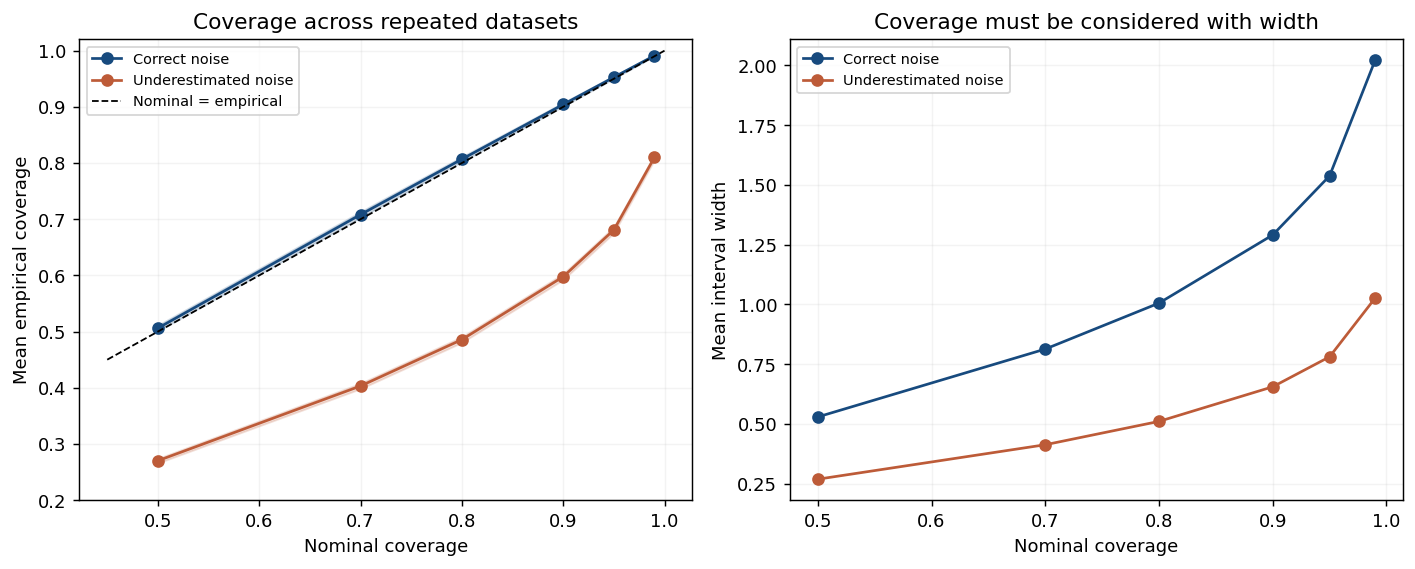

In [5]:
levels = np.array([0.50, 0.70, 0.80, 0.90, 0.95, 0.99])
repetitions = 150
sim_rng = np.random.default_rng(SEED + 1)
scenarios = {'Correct noise': sigma_true, 'Underestimated noise': sigma_true / 2}
coverage_runs = {name: np.empty((repetitions, len(levels))) for name in scenarios}
width_runs = {name: np.empty((repetitions, len(levels))) for name in scenarios}
# Precompute linear maps because inputs and hyperparameters remain fixed.
maps = {}
for name, sigma_model in scenarios.items():
    factor = cho_factor(kernel(x_train, x_train) + (sigma_model**2 + 1e-10)*np.eye(len(x_train)))
    cross = kernel(x_train, x_test)
    mapping = cho_solve(factor, cross).T
    variance = np.maximum(1.2**2 - np.sum(cross * mapping.T, axis=0), 0) + sigma_model**2
    maps[name] = mapping, variance

for r in range(repetitions):
    train_response = truth(x_train) + sim_rng.normal(0, sigma_true, len(x_train))
    test_response = truth(x_test) + sim_rng.normal(0, sigma_true, len(x_test))
    for name, (mapping, variance) in maps.items():
        center = mapping @ train_response
        for j, level in enumerate(levels):
            coverage_runs[name][r, j], width_runs[name][r, j] = interval_metrics(center, variance, test_response, level)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, color in zip(scenarios, ['#174a7e', '#bd5b38']):
    avg = coverage_runs[name].mean(axis=0)
    se = coverage_runs[name].std(axis=0, ddof=1) / np.sqrt(repetitions)
    axes[0].plot(levels, avg, 'o-', color=color, label=name)
    axes[0].fill_between(levels, np.maximum(0, avg-2*se), np.minimum(1, avg+2*se), color=color, alpha=.18)
    axes[1].plot(levels, width_runs[name].mean(axis=0), 'o-', color=color, label=name)
axes[0].plot([.45, 1], [.45, 1], 'k--', linewidth=1, label='Nominal = empirical')
axes[0].set(xlabel='Nominal coverage', ylabel='Mean empirical coverage', title='Coverage across repeated datasets', ylim=(.2, 1.02))
axes[1].set(xlabel='Nominal coverage', ylabel='Mean interval width', title='Coverage must be considered with width')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.15)
fig.tight_layout()
plt.show()

j95 = np.flatnonzero(np.isclose(levels, .95))[0]
print('95% prediction intervals: mean coverage | MCSE | mean width')
for name in scenarios:
    values = coverage_runs[name][:, j95]
    print(f'{name:24s} {values.mean():.3f} | {values.std(ddof=1)/np.sqrt(repetitions):.4f} | {width_runs[name][:,j95].mean():.3f}')
assert coverage_runs['Correct noise'][:,j95].mean() > coverage_runs['Underestimated noise'][:,j95].mean()
assert width_runs['Correct noise'][:,j95].mean() > width_runs['Underestimated noise'][:,j95].mean()


## Interpretation and exercises

Underestimating noise produces narrower prediction intervals and lower coverage in this simulation. Even with the correct noise level, the fixed true function is not sampled from the assumed GP prior, so exact nominal frequentist coverage is not guaranteed. We condition on fixed hyperparameters and do not include uncertainty from estimating them. Results cover the training-input range, not extrapolation or distribution shift.

1. Change the assumed noise level and rerun all cells. Compare coverage **and** width.
2. Replace the true function with a sharper curve. Does matching the noise suffice?
3. Extend the test range beyond the training inputs. Analyze coverage inside and outside the training range separately.

**Takeaway:** choose intervals for the prediction target and check their empirical performance on held-out observations.

## Reference

Rasmussen, C. E., and Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*, Chapter 2, MIT Press. [Chapter 2](https://gaussianprocess.org/gpml/chapters/RW2.pdf).

**Author:** Sheima Alameeri, PhD. Educational tutorial; no dissertation code or data.